In [18]:
import os 
import rasterio
import numpy as np
import matplotlib.pyplot as plt
##https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200#bands
# ========= CLASSIFICATION LOGIC =========

def classify_worldcover(array: np.ndarray) -> np.ndarray:
    """
    Map ESA WorldCover land cover classes to 3 simplified classes:
        0: Water
        1: Ground / Lowlands / Bare soil / Cropland
        2: Highlands / Vegetation / Buildings / Complex surfaces
    """
    WATER_CLASSES = [80]
    LOWLAND_CLASSES = [60, 40]  # Bare, Cropland
    HIGHLAND_CLASSES = [10, 20, 30, 50, 70, 90, 95, 100]

    classified = np.full(array.shape, 0, dtype=np.uint8)
    classified[np.isin(array, WATER_CLASSES)] = 0
    classified[np.isin(array, LOWLAND_CLASSES)] = 1
    classified[np.isin(array, HIGHLAND_CLASSES)] = 2
    #classified[classified == -1] = 255

    return classified#classified.astype(np.uint8)#classified

# ========= IO FUNCTIONS =========

def read_raster(path: str) -> tuple[np.ndarray, dict]:
    """
    Read a single-band raster and return the array and its profile.
    """
    with rasterio.open(path) as src:
        array = src.read(1).astype(np.int16)
        profile = src.profile
    return array, profile

def write_raster(path: str, array: np.ndarray, profile: dict) -> None:
    """
    Write a raster array to disk with the given profile.
    """
    profile = profile.copy()
    profile.update(dtype=rasterio.uint8, count=1, compress="lzw")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(array, 1)

# ========= VISUALIZATION =========

def plot_comparison(original: np.ndarray, classified: np.ndarray) -> None:
    """
    Plot the original and classified raster side by side.
    """
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))
    axs[0].imshow(original, cmap='tab20')
    axs[0].set_title("Original ESA WorldCover")
    axs[0].axis("off")

    axs[1].imshow(classified, cmap='viridis', vmin=0, vmax=2)
    axs[1].set_title("Reclassified (3 classes)\n0: Water, 1: Ground, 2: High surface")
    axs[1].axis("off")

    plt.tight_layout()
    plt.show()

# ========= WRAPPER =========

def reclassify_worldcover_3class(input_path: str, output_path: str, show_plot: bool = True) -> np.ndarray:
    """
    High-level function to run the full classification pipeline.
    """
    data, profile = read_raster(input_path)
    classified = classify_worldcover(data)
    write_raster(output_path, classified, profile)
    if show_plot:
        plot_comparison(data, classified)
    return classified

In [ ]:
from uvars import wcover_fn,edem_fn,tgap_fn,traw_fn
import os 
from os.path import join

In [11]:
labelc_dir = 'labelC'
os.makedirs(labelc_dir, exist_ok=True)

In [15]:
mask3c_fn = join(labelc_dir,wcover_fn.split('/')[-1].replace('.tif', '_3C.tif'))
mask3c_fn

'labelC/N13E103_esawc_3C.tif'

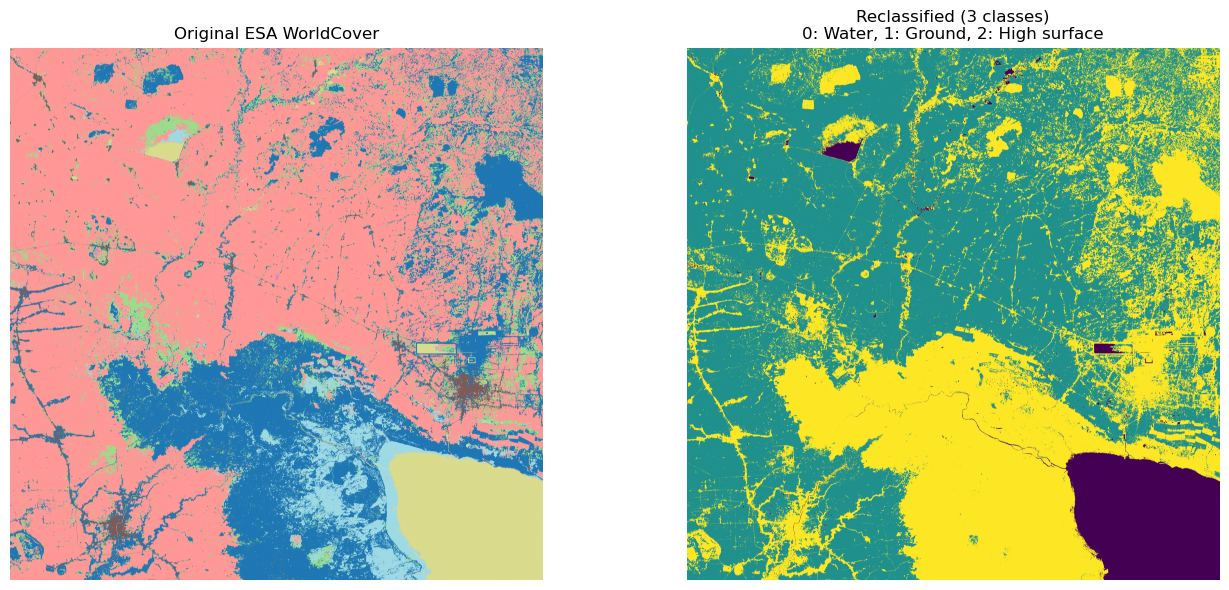

In [17]:
mask3c = reclassify_worldcover_3class(
    input_path=wcover_fn,
    output_path=mask3c_fn,
    show_plot=True
)
# improve the plots here 

In [24]:
def mask_highland_pixels(
    target_raster_path: str,
    mask_raster_path: str,
    output_path: str,
    nodata_value: float = -9999.0,
    lthresh: float = -20
):
    """
    Use a 3-class mask to remove class-2 (highland) and 255 (nodata) pixels from a target raster.
    
    Parameters:
        target_raster_path (str): Path to the raster you want to mask.
        mask_raster_path (str): Path to the 3-class mask raster.
        output_path (str): Path to save the masked raster.
        nodata_value (float, optional): Nodata value to write. If None, will use original raster's nodata.
    """
    with rasterio.open(target_raster_path) as target_src, rasterio.open(mask_raster_path) as mask_src:
        data = target_src.read(1)
        mask = mask_src.read(1)

        profile = target_src.profile.copy()
        if nodata_value is None:
            nodata_value = profile.get("nodata", -9999.0)
        profile.update(nodata=nodata_value)

        # Create masked array where class 2 or 255 in mask -> nodata
        masked_data = np.where((mask == 2) | (mask == 255), nodata_value, data)
        masked_data[masked_data < lthresh] = -9999.0

        # Write output
        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(masked_data, 1)

    return masked_data

In [25]:
edem3c_fn = join(labelc_dir,edem_fn.split('/')[-1].replace('.tif', '_3C.tif'))
mask3c_fn,edem3c_fn

('labelC/N13E103_esawc_3C.tif', 'labelC/N13E103_edem_egm_3C.tif')

In [26]:
edem3c = mask_highland_pixels(
    target_raster_path= edem_fn,
    mask_raster_path =mask3c_fn,
    output_path=edem3c_fn,
    )